# Тема 3. Применение условных вероятностей в анализе данных
> На некотором наборе данных (выбрать самостоятельно, можно: https://www.kaggle.com/datasets) продемонстрировать применение условных вероятностей (см. пример с рейтингом автомобилей по типу кузова, Notebook с примером "Титаника"). Рассматриваемый набор данных необходимо описать (назначение, описание признаков).


# Теория вероятностей на примере данных об успеваемости и отчислении студентов
Набор данных содержит 100 000 записей о студентах высших учебных заведений. Признаки описывают академическую успеваемость, социально-экономическое положение, вовлечённость в учёбу, форму обучения и благополучие студента.
https://www.kaggle.com/datasets/mohankrishnathalla/student-academic-performance-and-dropout-risk

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Загрузка данных и их описание

In [42]:
df = pd.read_csv('Data/student_dropout_risk_2026.csv')

print("Размерность данных:", df.shape)
print("\nСтолбцы:", df.columns.tolist())
df.info()

Размерность данных: (100000, 34)

Столбцы: ['person_id', 'age', 'gender', 'nationality', 'first_generation', 'disability_status', 'family_income_level', 'scholarship_holder', 'tuition_up_to_date', 'part_time_job', 'weekly_work_hours', 'course_type', 'study_mode', 'semester', 'international_student', 'admission_grade', 'previous_qualification_grade', 'units_enrolled', 'units_passed', 'units_failed', 'gpa_semester_1', 'gpa_semester_2', 'attendance_rate', 'assignments_submitted_rate', 'library_visits_per_month', 'lms_logins_per_week', 'extracurricular_activities', 'missed_deadlines', 'stress_level', 'mental_health_support', 'satisfaction_score', 'commute_time_mins', 'sleep_hours', 'dropout']
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age               

In [43]:
df.head()

,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0


In [44]:
print("Пропущенные значения:")
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100
pd.DataFrame({'Количество пропусков': missing_data,
              'Процент пропусков': missing_percent.round(2)})

Пропущенные значения:


,Количество пропусков,Процент пропусков
person_id,0,0.0
age,0,0.0
gender,0,0.0
nationality,0,0.0
first_generation,0,0.0
disability_status,0,0.0
family_income_level,0,0.0
scholarship_holder,0,0.0
tuition_up_to_date,0,0.0
part_time_job,0,0.0


## Сводная таблица для первоначального взгляда

In [45]:
print("Доля отчисленных по уровню дохода семьи и наличию подработки:")
pivot = pd.pivot_table(
    df,
    values='dropout',
    index=['family_income_level'],
    columns=['part_time_job'],
    aggfunc='mean',
    fill_value=0
)
pivot.round(4)

Доля отчисленных по уровню дохода семьи и наличию подработки:


part_time_job,0,1
family_income_level,,
High,0.1637,0.2664
Low,0.3476,0.4859
Middle,0.2435,0.3644


## Расчёт вероятностей

### Простые вероятности

In [46]:
# P(Отчислен) - общая вероятность отчисления
P_Dropout = df['dropout'].mean()
print(f"P(Dropout) = {P_Dropout:.3f}")

P(Dropout) = 0.320


In [47]:
# P(Доход) - вероятность быть студентом из семьи с каждым уровнем дохода
for income in ['Low', 'Middle', 'High']:
    P_Income = (df['family_income_level']==income).mean()
    print(f"P(Income={income}) = {P_Income:.3f}")

P(Income=Low) = 0.348
P(Income=Middle) = 0.402
P(Income=High) = 0.250


In [48]:
# P(Подработка) - вероятность иметь или не иметь подработку
for job in sorted(df['part_time_job'].unique()):
    P_Job = (df['part_time_job']==job).mean()
    print(f"P(Part_time_job={job}) = {P_Job:.3f}")

P(Part_time_job=0) = 0.518
P(Part_time_job=1) = 0.482


### Условные вероятности

#### Задача 1

Какова вероятность отчисления, если студент из семьи с низким доходом? $P_{Low}(Dropout)$

Формула:

$$P_{Low}(Dropout) = \frac{P(Dropout \cdot Low)}{P(Low)}$$

In [49]:
# Способ 1: Вручную по формуле
P_Low = (df['family_income_level']=='Low').mean()
P_Dropout_and_Low = ((df['dropout']==1) & (df['family_income_level']=='Low')).mean()
P_Dropout_if_Low = P_Dropout_and_Low / P_Low
print(f"P(Dropout | Low), рассчитанная вручную: {P_Dropout_if_Low:.3f}")

# Способ 2: Через фильтр
low = df[df['family_income_level']=='Low']
P_P_Dropout_if_Low = low['dropout'].mean()
print(f"P(Dropout | Low), рассчитанная через фильтр: {P_P_Dropout_if_Low:.3f}")

P(Dropout | Low), рассчитанная вручную: 0.429
P(Dropout | Low), рассчитанная через фильтр: 0.429


#### Задача 2.

Какова вероятность отчисления, если студент из семьи с высоким доходом? $P_{High}(Dropout)$

Формула:

$$P_{High}(Dropout) = \frac{P(Dropout \cdot High)}{P(High)}$$

In [50]:
# Способ 1: Вручную по формуле
P_High = (df['family_income_level']=='High').mean()
P_Dropout_and_High = ((df['dropout']==1) & (df['family_income_level']=='High')).mean()
P_Dropout_if_High = P_Dropout_and_High / P_High
print(f"P(Dropout | High), рассчитанная вручную: {P_Dropout_if_High:.3f}")

# Способ 2: Через фильтр
high = df[df['family_income_level']=='High']
P_P_Dropout_if_High = high['dropout'].mean()
print(f"P(Dropout | High), рассчитанная через фильтр: {P_P_Dropout_if_High:.3f}")

P(Dropout | High), рассчитанная вручную: 0.200
P(Dropout | High), рассчитанная через фильтр: 0.200


#### Задача 3.

Какова вероятность отчисления, если у студента есть подработка? $P_{Job=1}(Dropout)$

Формула:

$$P_{Job=1}(Dropout) = \frac{P(Dropout \cdot Job=1)}{P(Job=1)}$$

In [51]:
# Способ 1: Вручную по формуле
P_Job1 = (df['part_time_job']==1).mean()
P_Dropout_and_Job1 = ((df['dropout']==1) & (df['part_time_job']==1)).mean()
P_Dropout_if_Job1 = P_Dropout_and_Job1 / P_Job1
print(f"P(Dropout | Job=1), рассчитанная вручную: {P_Dropout_if_Job1:.3f}")

# Способ 2: Через фильтр
job1 = df[df['part_time_job']==1]
P_P_Dropout_if_Job1 = job1['dropout'].mean()
print(f"P(Dropout | Job=1), рассчитанная через фильтр: {P_P_Dropout_if_Job1:.3f}")

P(Dropout | Job=1), рассчитанная вручную: 0.398
P(Dropout | Job=1), рассчитанная через фильтр: 0.398


### Обобщение вычисления условных вероятностей

Поскольку при вычислении условных вероятностей прослеживается общая схема их расчёта, напишем **функцию определения условных вероятностей**, которая будет принимать:
* `df` – датафрейм;
* `condition_col` – название столбца с произошедшим событием;
* `condition_val` – значение произошедшего события;
* `target_col` – название столбца с целевым событием;
* `target_val` – значение целевого события.

In [52]:
def conditional_probability(df, condition_col, condition_val,
                            target_col, target_val=1):
    """
    Вычисляет условную вероятность
    P(target_col=target_val | condition_col=condition_val)
    """
    subset = df[df[condition_col]==condition_val]
    if len(subset) == 0:
        return 0
    return (subset[target_col]==target_val).mean()

In [53]:
print("УСЛОВНЫЕ ВЕРОЯТНОСТИ ОТЧИСЛЕНИЯ:")
print("=" * 50)

# По уровню дохода
print("\nПо уровню дохода семьи:")
for income in ['Low', 'Middle', 'High']:
    prob = conditional_probability(df, 'family_income_level', income, 'dropout')
    print(f"  P(Dropout|Income={income}) = {prob:.3f}")

# По наличию подработки
print("\nПо наличию подработки:")
for job in sorted(df['part_time_job'].unique()):
    prob = conditional_probability(df, 'part_time_job', job, 'dropout')
    print(f"  P(Dropout|Part_time_job={job}) = {prob:.3f}")

# По полу
print("\nПо полу:")
for gender in sorted(df['gender'].unique()):
    prob = conditional_probability(df, 'gender', gender, 'dropout')
    print(f"  P(Dropout|Gender={gender}) = {prob:.3f}")

УСЛОВНЫЕ ВЕРОЯТНОСТИ ОТЧИСЛЕНИЯ:

По уровню дохода семьи:
  P(Dropout|Income=Low) = 0.429
  P(Dropout|Income=Middle) = 0.300
  P(Dropout|Income=High) = 0.200

По наличию подработки:
  P(Dropout|Part_time_job=0) = 0.247
  P(Dropout|Part_time_job=1) = 0.398

По полу:
  P(Dropout|Gender=Female) = 0.319
  P(Dropout|Gender=Male) = 0.320
  P(Dropout|Gender=Other) = 0.334


### Формула полной вероятности
**Задача**. Мы знаем вероятность отчисления для каждого уровня дохода семьи. Как, используя эту информацию, найти общую вероятность отчисления $P(Dropout)$?

Формула полной вероятности:

$P(A) = \sum P_{B_i}(A) \cdot P(B_i)$, где $B_i$ образуют полную группу несовместных событий.

В нашем случае: $\{B_1, B_2, B_3\} = \{Income = Low,\ Income = Middle,\ Income = High\}$

$$P(Dropout) = P(Dropout|Low) \cdot P(Low) + P(Dropout|Middle) \cdot P(Middle) + P(Dropout|High) \cdot P(High)$$

In [54]:
print("ФОРМУЛА ПОЛНОЙ ВЕРОЯТНОСТИ:")
print("P(Dropout) = Σ P(Dropout|Income=i) * P(Income=i)")
print("=" * 50)

total_prob = 0
prob_details = []

for income in ['Low', 'Middle', 'High']:
    # P(Income = i)
    P_income = (df['family_income_level']==income).mean()
    # P(Dropout | Income = i)
    P_dropout_given_income = conditional_probability(df, 'family_income_level',
                                                     income, 'dropout')

    # Вклад этой группы
    contribution = P_dropout_given_income * P_income
    total_prob += contribution

    prob_details.append({
        'Income': income,
        'P(Income)': P_income,
        'P(Dropout|Income)': P_dropout_given_income,
        'Вклад': contribution
    })

prob_df = pd.DataFrame(prob_details)
print(prob_df.round(3))

print(f"\nОбщая вероятность отчисления, рассчитанная по формуле полной вероятности: {total_prob:.3f}")
print(f"Общая вероятность отчисления, рассчитанная напрямую из данных: {df['dropout'].mean():.3f}")

ФОРМУЛА ПОЛНОЙ ВЕРОЯТНОСТИ:
P(Dropout) = Σ P(Dropout|Income=i) * P(Income=i)
   Income  P(Income)  P(Dropout|Income)  Вклад
0     Low      0.348              0.429  0.149
1  Middle      0.402              0.300  0.121
2    High      0.250              0.200  0.050

Общая вероятность отчисления, рассчитанная по формуле полной вероятности: 0.320
Общая вероятность отчисления, рассчитанная напрямую из данных: 0.320


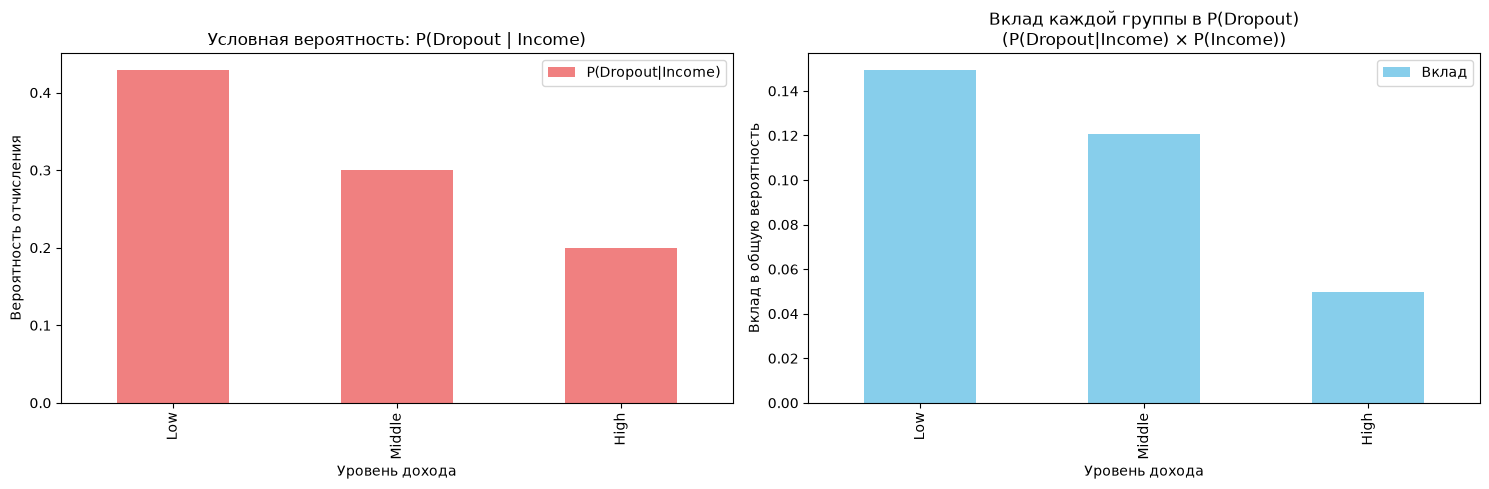

In [55]:
# Визуализируем вклад групп
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Левая часть: P(Dropout | Income)
prob_df.plot(x='Income', y='P(Dropout|Income)', kind='bar', ax=ax1, color='lightcoral')
ax1.set_title('Условная вероятность: P(Dropout | Income)')
ax1.set_ylabel('Вероятность отчисления')
ax1.set_xlabel('Уровень дохода')

# Правая часть: Вклад в общую вероятность
prob_df.plot(x='Income', y='Вклад', kind='bar', ax=ax2, color='skyblue')
ax2.set_title('Вклад каждой группы в P(Dropout)\n(P(Dropout|Income) × P(Income))')
ax2.set_ylabel('Вклад в общую вероятность')
ax2.set_xlabel('Уровень дохода')

plt.tight_layout()
plt.show()

### Формула Байеса

**Задача**. Мы видим отчисленного студента. Информации о нём у нас нет, но мы хотим понять, из семьи с каким уровнем дохода он, скорее всего. Другими словами, мы хотим найти $P_{Dropout}(Income)$.

По теореме Байеса:
$$P_{Dropout}(Income = i) = \frac{P(Income = i) \cdot P_{Income=i}(Dropout)}{P(Dropout)}$$

In [56]:
print("ТЕОРЕМА БАЙЕСА:")
print("P(Income | Dropout) = [P(Dropout | Income) × P(Income)] / P(Dropout)")
print("=" * 50)

P_D = df['dropout'].mean()

bayes_results = []

for income in ['Low', 'Middle', 'High']:
    P_A = (df['family_income_level']==income).mean()
    P_B_given_A = conditional_probability(df, 'family_income_level', income, 'dropout')

    P_A_given_B = (P_B_given_A * P_A) / P_D

    bayes_results.append({
        'Income': income,
        'P(Income)': P_A,
        'P(Dropout|Income)': P_B_given_A,
        'P(Income|Dropout)': P_A_given_B
    })

bayes_df = pd.DataFrame(bayes_results)
print("Результаты применения теоремы Байеса:")
print(bayes_df.round(3))

ТЕОРЕМА БАЙЕСА:
P(Income | Dropout) = [P(Dropout | Income) × P(Income)] / P(Dropout)
Результаты применения теоремы Байеса:
   Income  P(Income)  P(Dropout|Income)  P(Income|Dropout)
0     Low      0.348              0.429              0.467
1  Middle      0.402              0.300              0.377
2    High      0.250              0.200              0.156


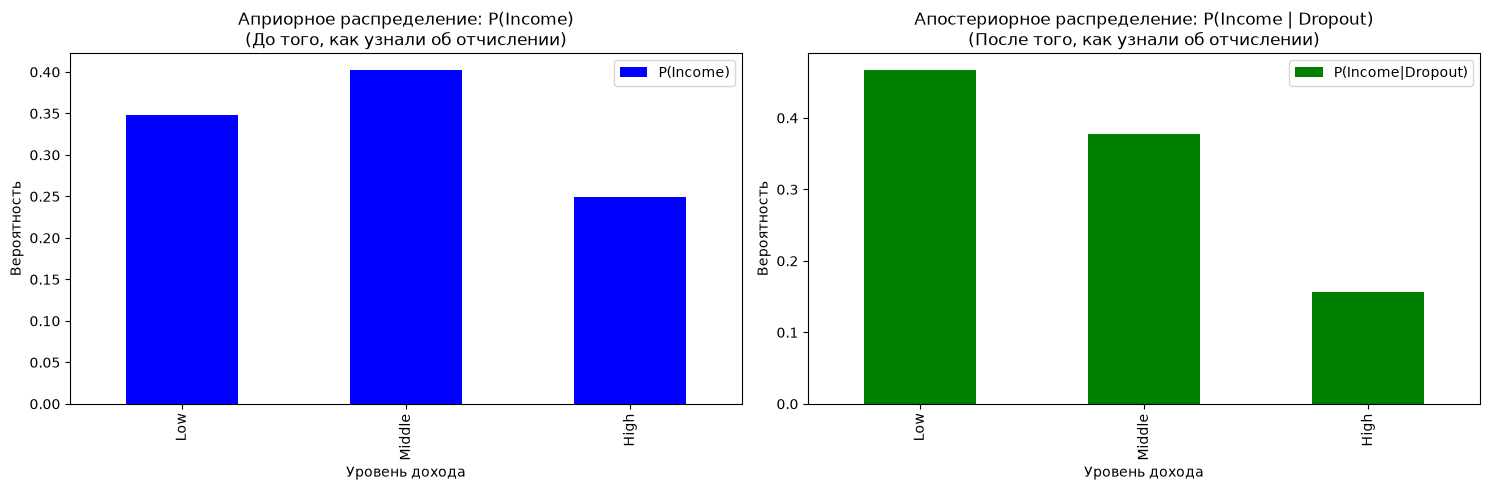

In [57]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Априорное распределение
bayes_df.plot(x='Income', y='P(Income)', kind='bar', ax=ax1, color='blue')
ax1.set_title('Априорное распределение: P(Income)\n(До того, как узнали об отчислении)')
ax1.set_ylabel('Вероятность')
ax1.set_xlabel('Уровень дохода')

# Апостериорное распределение
bayes_df.plot(x='Income', y='P(Income|Dropout)', kind='bar', ax=ax2, color='green')
ax2.set_title('Апостериорное распределение: P(Income | Dropout)\n(После того, как узнали об отчислении)')
ax2.set_ylabel('Вероятность')
ax2.set_xlabel('Уровень дохода')

plt.tight_layout()
plt.show()